## Project 4: What Separates a Slow Glioma From an Aggressive One?
This notebook loads three downloads from cBioPortal and joins them into one clean table.

- **lgggbm_tcga_pub** has each patient's labels (tumor grade, IDH status, subtype) and survival, from the Ceccarelli 2016 paper.
- **lgg_tcga_pan_can_atlas_2018** has gene activity for the lower grade gliomas.
- **gbm_tcga_pan_can_atlas_2018** has gene activity for the glioblastomas.

It then looks at who is in the data, how many patients have each label, and what survival looks like. Nothing here is a result yet. The goal is to check the data before we trust it.


In [52]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

plt.rcParams["font.size"] = 20

purple = "#5B3A8C"
dark_blue = "#1F3A6B"
light_purple = "#A794C9"

Path("csv").mkdir(exist_ok=True)
Path("figures").mkdir(exist_ok=True)
print('Done')

Done


In [53]:
#Set the data folders - making sure they are in the correct place
data_dir = Path.home() / "Desktop" / "PROJECT_4_PORT"

pub_dir = data_dir / "lgggbm_tcga_pub"
lgg_dir = data_dir / "lgg_tcga_pan_can_atlas_2018"
gbm_dir = data_dir / "gbm_tcga_pan_can_atlas_2018"

for folder in [pub_dir, lgg_dir, gbm_dir]:
    print(folder.name, "found:", folder.exists())
    if not folder.exists():
        raise FileNotFoundError("Could not find " + str(folder) + ". Check data_dir above.")

lgggbm_tcga_pub found: True
lgg_tcga_pan_can_atlas_2018 found: True
gbm_tcga_pan_can_atlas_2018 found: True


### Loading the patient labels and survival
The paper's download comes as two small tables. One row per patient has age, sex, and survival. The other has the labels from the paper, like tumor grade and IDH status. Lines that start with `#` are descriptions of the columns, so I skipped them.

Survival is stored as two columns. `OS_MONTHS` is how many months the patient was followed, and `OS_STATUS` says whether they were still alive at the end. Patients who were still alive are not "survivors forever." We just don't know yet when they will die. That is why there is an `event` column, which is 1 if the patient died and 0 if they were still living.

In [54]:
patients = pd.read_csv(pub_dir / "data_clinical_patient.txt", sep="\t", comment="#")
samples = pd.read_csv(pub_dir / "data_clinical_sample.txt", sep="\t", comment="#")

print("Patients in the patient file:", len(patients))
print("Rows in the sample file:", len(samples))
print("Patients in the sample file:", samples["PATIENT_ID"].nunique())
print("Patients with more than one sample row:", int(samples["PATIENT_ID"].duplicated().sum()))

# one row per patient, with the labels and the survival together
labels = patients.merge(samples.drop_duplicates("PATIENT_ID"), on="PATIENT_ID", how="left")

# event is 1 if the patient died, 0 if they were still living, and blank if unknown
status = labels["OS_STATUS"].astype("string")
labels["event"] = np.where(status.isna(), np.nan, status.str.startswith("1").astype(float))

print("Patients in the labels table:", len(labels))

Patients in the patient file: 1122
Rows in the sample file: 1122
Patients in the sample file: 1122
Patients with more than one sample row: 0
Patients in the labels table: 1122


### Load the gene activity
Each number in the expression files is how active one gene was in one tumor. The unit is called RSEM, which is roughly a count of how many copies of that gene's message the sequencer saw. Counts can be tiny or huge, so we take `log2(count + 1)`. That squashes the huge numbers down so a gene going from 10 to 20 counts looks like the same step as 1,000 to 2,000, which is what we care about biologically.

A few cleanups are needed.

- Sample names end in `-01` for the main tumor and `-02` for a tumor that came back. We keep only `-01`, so each patient appears once, at diagnosis.
- Some gene names show up twice. We keep the row with the higher average activity.
- A few genes have blank values. We drop those genes.

In [55]:
def load_expression(folder, cohort):
    expr = pd.read_csv(folder / "data_mrna_seq_v2_rsem.txt", sep="\t")
    expr = expr.drop(columns=["Entrez_Gene_Id"])
    print(cohort, "genes in file:", len(expr))

    # drop rows with no gene name
    expr = expr.dropna(subset=["Hugo_Symbol"])

    # keep the main tumor sample only
    tumor_columns = [c for c in expr.columns if c.endswith("-01")]
    print(cohort, "tumor samples kept:", len(tumor_columns), "of", len(expr.columns) - 1)
    expr = expr[["Hugo_Symbol"] + tumor_columns]

    # for repeated gene names, keep the row with the highest average
    expr["average"] = expr[tumor_columns].mean(axis=1)
    expr = expr.sort_values("average", ascending=False).drop_duplicates("Hugo_Symbol")
    expr = expr.drop(columns="average").set_index("Hugo_Symbol")

    # drop genes with blank values
    before = len(expr)
    expr = expr.dropna(how="any")
    print(cohort, "genes dropped for blanks:", before - len(expr))

    # name each column by patient (first 12 characters, like TCGA-CS-4938)
    expr.columns = [c[:12] for c in expr.columns]
    expr = expr.loc[:, ~expr.columns.duplicated()]
    return expr.astype("float32")

lgg_expr = load_expression(lgg_dir, "LGG")
gbm_expr = load_expression(gbm_dir, "GBM")

# put the two cohorts side by side, keeping genes that both files have
expression = pd.concat([lgg_expr, gbm_expr], axis=1, join="inner")
log_expr = np.log2(expression + 1)

cohort_of = {p: "LGG" for p in lgg_expr.columns}
cohort_of.update({p: "GBM" for p in gbm_expr.columns})

print("Genes in both cohorts:", log_expr.shape[0])
print("Patients with gene activity:", log_expr.shape[1])

LGG genes in file: 20531
LGG tumor samples kept: 514 of 514
LGG genes dropped for blanks: 0


/var/folders/_3/_4n4hdlj1z92xtwd12z3_j1h0000gn/T/ipykernel_8558/4124823326.py:15: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  expr["average"] = expr[tumor_columns].mean(axis=1)


GBM genes in file: 20531
GBM tumor samples kept: 153 of 160
GBM genes dropped for blanks: 0
Genes in both cohorts: 20511
Patients with gene activity: 667


/var/folders/_3/_4n4hdlj1z92xtwd12z3_j1h0000gn/T/ipykernel_8558/4124823326.py:15: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  expr["average"] = expr[tumor_columns].mean(axis=1)


### Check the numbers look right
RSEM values should never be negative, and most genes should be zero or low in a lot of patients. After the log, the biggest values should land somewhere around 15 to 20.

In [56]:
values = expression.to_numpy()
print("Smallest value:", float(values.min()))
print("Largest value:", round(float(values.max())))
print("Share of values that are exactly zero:", round(float((values == 0).mean()) * 100, 1), "%")
print("Largest value after log2:", round(float(log_expr.to_numpy().max()), 1))

Smallest value: 0.0
Largest value: 2554530
Share of values that are exactly zero: 13.7 %
Largest value after log2: 21.3


### Match gene activity to labels
Now we line up the two sources by patient ID. A patient is only useful for our question if we have both their gene activity and their labels, so this shows how many we keep and how many drop out.

In [57]:
labels["has_expression"] = labels["PATIENT_ID"].isin(log_expr.columns)

print("Patients with labels:", len(labels))
print("Patients with gene activity:", log_expr.shape[1])
print("Patients with both:", int(labels["has_expression"].sum()))
print("Patients with labels but no gene activity:", int((~labels["has_expression"]).sum()))
print("Patients with gene activity but no labels:", len(set(log_expr.columns) - set(labels["PATIENT_ID"])))

patient_table = labels[labels["has_expression"]].copy().reset_index(drop=True)
patient_table["cohort"] = patient_table["PATIENT_ID"].map(cohort_of)

# put the gene activity columns in the same order as the patient table
log_expr = log_expr[patient_table["PATIENT_ID"]]

print("Patients kept:", len(patient_table))

Patients with labels: 1122
Patients with gene activity: 667
Patients with both: 667
Patients with labels but no gene activity: 455
Patients with gene activity but no labels: 0
Patients kept: 667


### What is missing?
Some labels are blank for some patients. This shows how many, so we know which labels we can lean on.

In [58]:
key_columns = ["GRADE", "IDH_STATUS", "IDH_CODEL_SUBTYPE", "TRANSCRIPTOME_SUBTYPE",
               "OS_MONTHS", "OS_STATUS", "AGE", "SEX"]

missing = patient_table[key_columns].isna().sum()
print("Missing values among the", len(patient_table), "patients:")
print(missing.to_string())

Missing values among the 667 patients:
GRADE                     60
IDH_STATUS                 7
IDH_CODEL_SUBTYPE         12
TRANSCRIPTOME_SUBTYPE    139
OS_MONTHS                 60
OS_STATUS                 60
AGE                       60
SEX                       60


In [59]:
no_expression = labels[~labels["has_expression"]]
print("Patients with labels but no gene activity, by study:")
print(no_expression["STUDY"].value_counts(dropna=False).to_string())

no_survival = patient_table[patient_table["OS_MONTHS"].isna()]
print()
print("Patients kept but with no survival data:", len(no_survival))
print(no_survival["cohort"].value_counts().to_string())

# does the gene activity download have survival for these patients?
for name, folder in [("LGG", lgg_dir), ("GBM", gbm_dir)]:
    other = pd.read_csv(folder / "data_clinical_patient.txt", sep="\t", comment="#")
    print()
    print(name, "patient file columns:", list(other.columns))
    if "OS_MONTHS" in other.columns:
        have = other[other["PATIENT_ID"].isin(no_survival["PATIENT_ID"]) & other["OS_MONTHS"].notna()]
        print(name, "patients missing survival here that it has:", len(have))

Patients with labels but no gene activity, by study:
STUDY
Glioblastoma multiforme     453
Brain Lower Grade Glioma      2

Patients kept but with no survival data: 60
cohort
LGG    59
GBM     1

LGG patient file columns: ['PATIENT_ID', 'SUBTYPE', 'CANCER_TYPE_ACRONYM', 'OTHER_PATIENT_ID', 'AGE', 'SEX', 'AJCC_PATHOLOGIC_TUMOR_STAGE', 'AJCC_STAGING_EDITION', 'DAYS_LAST_FOLLOWUP', 'DAYS_TO_BIRTH', 'DAYS_TO_INITIAL_PATHOLOGIC_DIAGNOSIS', 'ETHNICITY', 'FORM_COMPLETION_DATE', 'HISTORY_NEOADJUVANT_TRTYN', 'ICD_10', 'ICD_O_3_HISTOLOGY', 'ICD_O_3_SITE', 'INFORMED_CONSENT_VERIFIED', 'NEW_TUMOR_EVENT_AFTER_INITIAL_TREATMENT', 'PATH_M_STAGE', 'PATH_N_STAGE', 'PATH_T_STAGE', 'PERSON_NEOPLASM_CANCER_STATUS', 'PRIMARY_LYMPH_NODE_PRESENTATION_ASSESSMENT', 'PRIOR_DX', 'RACE', 'RADIATION_THERAPY', 'WEIGHT', 'IN_PANCANPATHWAYS_FREEZE', 'OS_STATUS', 'OS_MONTHS', 'DSS_STATUS', 'DSS_MONTHS', 'DFS_STATUS', 'DFS_MONTHS', 'PFS_STATUS', 'PFS_MONTHS', 'GENETIC_ANCESTRY_LABEL']
LGG patients missing survival here

In [60]:
other_clinical = pd.concat([
    pd.read_csv(folder / "data_clinical_patient.txt", sep="\t", comment="#")[["PATIENT_ID", "OS_MONTHS", "OS_STATUS", "AGE", "SEX"]]
    for folder in [lgg_dir, gbm_dir]
]).drop_duplicates("PATIENT_ID").set_index("PATIENT_ID")

# keep the paper's original survival for reference
patient_table["OS_MONTHS_paper"] = patient_table["OS_MONTHS"]
patient_table["OS_STATUS_paper"] = patient_table["OS_STATUS"]

# use the newer survival for everyone, and fall back to the paper's only if the newer one is blank
for column in ["OS_MONTHS", "OS_STATUS"]:
    newer = patient_table["PATIENT_ID"].map(other_clinical[column])
    print(column + ": patients using the paper's value instead:", int((newer.isna() & patient_table[column].notna()).sum()))
    patient_table[column] = newer.fillna(patient_table[column])

# age and sex only need their blanks filled
for column in ["AGE", "SEX"]:
    patient_table[column] = patient_table[column].fillna(patient_table["PATIENT_ID"].map(other_clinical[column]))

# rebuild the event column from the updated status
status = patient_table["OS_STATUS"].astype("string")
patient_table["event"] = np.where(status.isna(), np.nan, status.str.startswith("1").astype(float))

# how much did the update change?
changed_to_deceased = (patient_table["OS_STATUS_paper"].astype("string").str.startswith("0") & (patient_table["event"] == 1))
print()
print("Patients who were living in the paper but had died by the update:", int(changed_to_deceased.sum()))
print("Patients with survival now:", int(patient_table["OS_MONTHS"].notna().sum()), "of", len(patient_table))
print("Patients still missing survival:", int(patient_table["OS_MONTHS"].isna().sum()))

OS_MONTHS: patients using the paper's value instead: 0
OS_STATUS: patients using the paper's value instead: 0

Patients who were living in the paper but had died by the update: 47
Patients with survival now: 665 of 667
Patients still missing survival: 2


### Who is in the data?
These are the label counts that will shape our slow versus aggressive groups.

In [61]:
for column in ["cohort", "GRADE", "IDH_STATUS", "IDH_CODEL_SUBTYPE", "TRANSCRIPTOME_SUBTYPE"]:
    print(column + ":")
    print(patient_table[column].value_counts(dropna=False).to_string())
    print()

cohort:
cohort
LGG    514
GBM    153

GRADE:
GRADE
G3     240
G2     215
G4     152
NaN     60

IDH_STATUS:
IDH_STATUS
Mutant    426
WT        234
NaN         7

IDH_CODEL_SUBTYPE:
IDH_CODEL_SUBTYPE
IDHmut-non-codel    258
IDHwt               230
IDHmut-codel        167
NaN                  12

TRANSCRIPTOME_SUBTYPE:
TRANSCRIPTOME_SUBTYPE
PN     236
NaN    139
NE     111
ME      95
CL      86



Tumor grade and IDH subtype overlap but are not the same thing. This table shows how they line up. If the paper is right, the slow-growing grade 2 and 3 tumors should mostly carry the IDH mutation, and the grade 4 glioblastomas should mostly not.

In [62]:
grade_vs_subtype = pd.crosstab(patient_table["GRADE"].fillna("Missing"),
                               patient_table["IDH_CODEL_SUBTYPE"].fillna("Missing"),
                               margins=True)
print(grade_vs_subtype.to_string())

IDH_CODEL_SUBTYPE  IDHmut-codel  IDHmut-non-codel  IDHwt  Missing  All
GRADE                                                                 
G2                           80               114     19        2  215
G3                           69               104     67        0  240
G4                            0                 8    135        9  152
Missing                      18                32      9        1   60
All                         167               258    230       12  667


### What does survival look like?
This is the most important thing to understand about the data. For each group, we count how many patients died and how long people were followed.

In [63]:
survival_by_group = (patient_table.assign(group=patient_table["IDH_CODEL_SUBTYPE"].fillna("Missing"))
                     .groupby("group")
                     .agg(patients=("PATIENT_ID", "count"),
                          with_survival=("event", "count"),
                          deaths=("event", "sum"),
                          median_followup_months=("OS_MONTHS", "median")))

# share deceased only counts patients whose survival we actually know
survival_by_group["share_deceased"] = (survival_by_group["deaths"] / survival_by_group["with_survival"]).round(2)
survival_by_group["deaths"] = survival_by_group["deaths"].astype(int)
survival_by_group["median_followup_months"] = survival_by_group["median_followup_months"].round(1)
print(survival_by_group.to_string())


                  patients  with_survival  deaths  median_followup_months  share_deceased
group                                                                                    
IDHmut-codel           167            167      21                    23.2            0.13
IDHmut-non-codel       258            257      57                    27.5            0.22
IDHwt                  230            229     160                    12.6            0.70
Missing                 12             12       7                    15.1            0.58


### Three pictures
Patients per group, how many of them died, and how long people were followed.

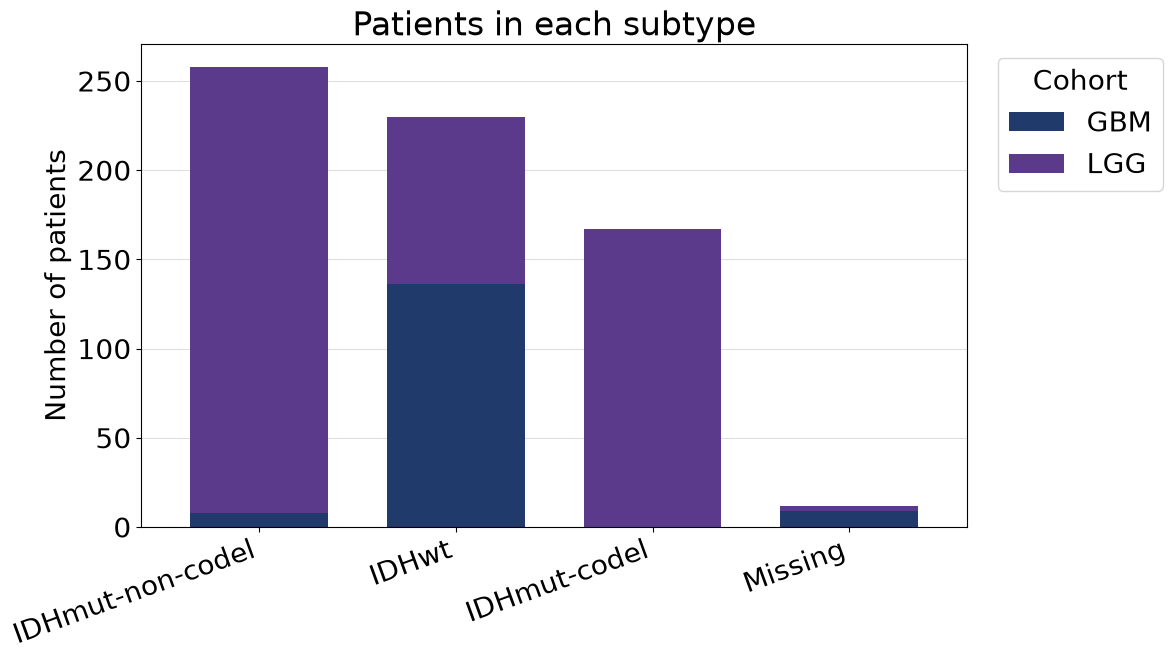

In [64]:
order = patient_table["IDH_CODEL_SUBTYPE"].fillna("Missing").value_counts().index.tolist()
group = patient_table["IDH_CODEL_SUBTYPE"].fillna("Missing")

# picture 1: patients per group, split by which download they came from
counts = pd.crosstab(group, patient_table["cohort"]).reindex(order)
fig, ax = plt.subplots(figsize=(12, 7))
counts.plot(kind="bar", stacked=True, ax=ax, color=[dark_blue, purple][: counts.shape[1]], width=0.7)
ax.set_title("Patients in each subtype")
ax.set_xlabel("")
ax.set_ylabel("Number of patients")
ax.set_xticklabels(order, rotation=20, ha="right")
ax.grid(True, axis="y", alpha=0.4)
ax.set_axisbelow(True)
ax.legend(title="Cohort", loc="upper left", bbox_to_anchor=(1.02, 1))
plt.tight_layout()
plt.savefig("figures/p4-patients-by-subtype.png", dpi=150, bbox_inches="tight")
plt.show()

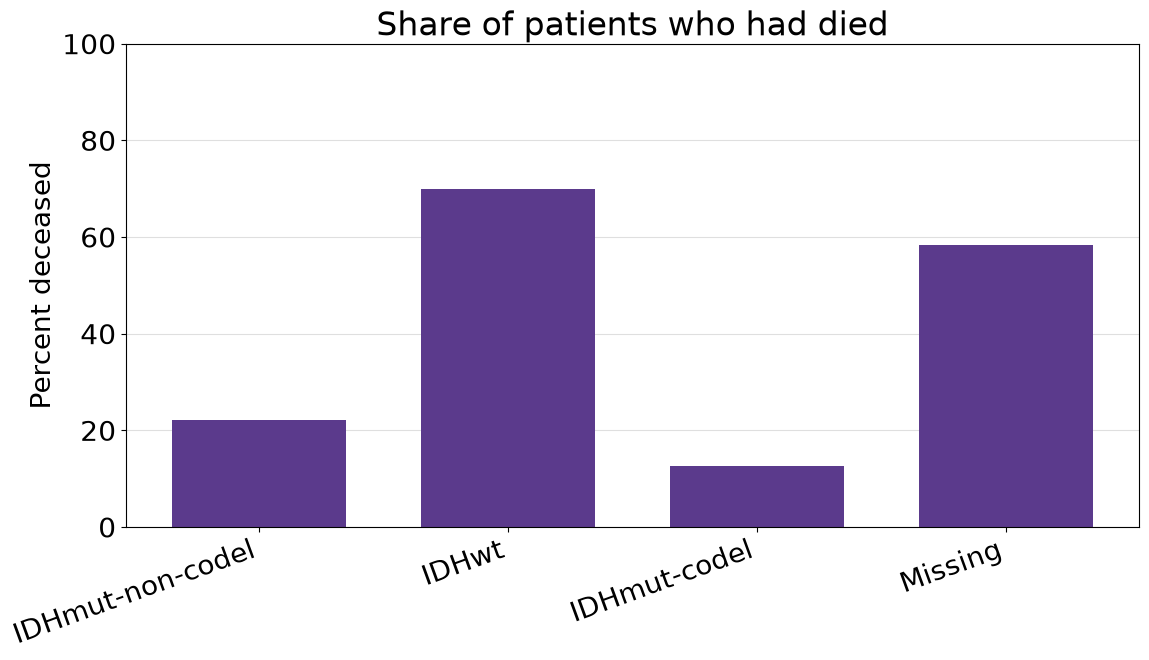

In [65]:
# picture 2: share of patients who had died by the end of follow-up
share = patient_table.assign(group=group).groupby("group")["event"].mean().reindex(order)
fig, ax = plt.subplots(figsize=(12, 7))
ax.bar(range(len(order)), share.values * 100, color=purple, width=0.7)
ax.set_xticks(range(len(order)))
ax.set_xticklabels(order, rotation=20, ha="right")
ax.set_title("Share of patients who had died")
ax.set_ylabel("Percent deceased")
ax.set_ylim(0, 100)
ax.grid(True, axis="y", alpha=0.4)
ax.set_axisbelow(True)
plt.tight_layout()
plt.savefig("figures/p4-share-deceased-by-subtype.png", dpi=150, bbox_inches="tight")
plt.show()

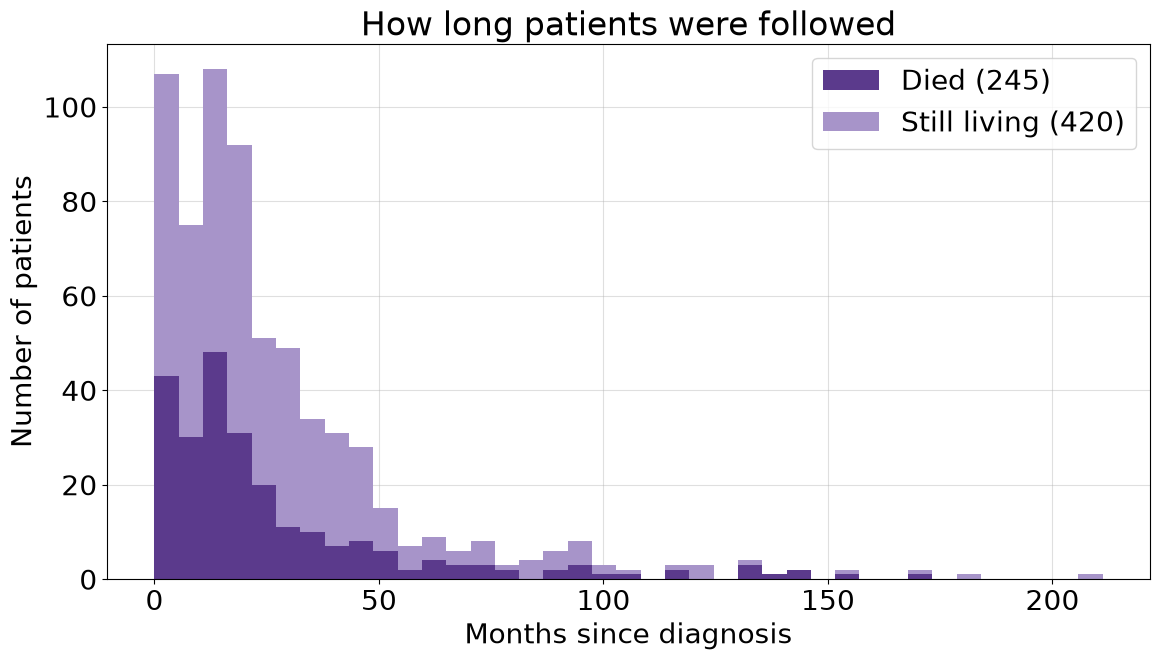

In [66]:
# picture 3: how long people were followed, split by whether they died
died = patient_table.loc[patient_table["event"] == 1, "OS_MONTHS"].dropna()
living = patient_table.loc[patient_table["event"] == 0, "OS_MONTHS"].dropna()

fig, ax = plt.subplots(figsize=(12, 7))
bins = np.linspace(0, patient_table["OS_MONTHS"].max(), 40)
ax.hist([died, living], bins=bins, stacked=True, color=[purple, light_purple],
        label=["Died (" + str(len(died)) + ")", "Still living (" + str(len(living)) + ")"])
ax.set_title("How long patients were followed")
ax.set_xlabel("Months since diagnosis")
ax.set_ylabel("Number of patients")
ax.grid(True, alpha=0.4)
ax.set_axisbelow(True)
ax.legend(loc="upper right")
plt.tight_layout()
plt.savefig("figures/p4-followup-months.png", dpi=150, bbox_inches="tight")
plt.show()

### One last check that the join worked
If gene activity is matched to the right patients, a few well-known genes should behave the way the biology says. EGFR and CHI3L1 are usually much more active in the aggressive IDH wild-type tumors, and MKI67 (a marker of cells dividing) should be higher there too. If these numbers look random, something went wrong with the matching.

In [67]:
check_genes = [g for g in ["EGFR", "CHI3L1", "MKI67", "TERT", "IDH1"] if g in log_expr.index]
print("Genes checked:", check_genes)

check = log_expr.loc[check_genes].T
check["group"] = group.values
print()
print("Median log2 activity by subtype:")
print(check.groupby("group").median().round(2).to_string())

Genes checked: ['EGFR', 'CHI3L1', 'MKI67', 'TERT', 'IDH1']

Median log2 activity by subtype:
Hugo_Symbol        EGFR  CHI3L1  MKI67  TERT   IDH1
group                                              
IDHmut-codel      11.32    7.30   8.17  2.51  10.63
IDHmut-non-codel  10.99    7.63   8.04  0.00  10.61
IDHwt             12.16   14.68   9.42  2.98  11.29
Missing           11.60   13.09   9.81  0.00  11.30


### Save for the next step
The patient table is small, so it goes in the `csv` folder. The gene activity table is big, so it goes in a `processed` folder next to your data, outside your GitHub folder.

In [68]:
processed_dir = data_dir / "processed"
processed_dir.mkdir(exist_ok=True)

patient_table.to_csv("csv/patient_table.csv", index=False)
log_expr.to_csv(processed_dir / "expression_log2.csv.gz")

print("Saved csv/patient_table.csv with", len(patient_table), "patients")
print("Saved", processed_dir / "expression_log2.csv.gz", "with", log_expr.shape[0], "genes")

Saved csv/patient_table.csv with 667 patients
Saved /Users/kayliehynes/Desktop/PROJECT_4_PORT/processed/expression_log2.csv.gz with 20511 genes
